**Binôme : Enora & Enora**

# Atelier 2 — Profiler les données e-commerce avec Pandas
## Projet fil rouge : BigData Commerce Analytics

**Niveau :** B2 · **Modalité :** individuel ou binôme · 

### Mission
Vous êtes Data Analysts. Vous recevez une table de lignes de panier issue de DummyJSON. Vous devez en comprendre la granularité, vérifier sa structure, mesurer sa qualité et proposer un plan de nettoyage avant stockage dans MongoDB et traitement avec Spark.

### Objectifs pédagogiques
- Charger un CSV et contrôler sa structure.
- Distinguer ligne, panier, utilisateur et produit.
- Mesurer valeurs manquantes, doublons et incohérences.
- Détecter valeurs atypiques et erreurs de typage.
- Documenter les transformations sans détruire les données brutes.

> **Avertissement métier :** le fichier représente des lignes de paniers de démonstration. Ce n'est pas un historique réel de commandes. La colonne `order_date` est synthétique si le fichier a été généré par le script de collecte. Ne l'utilisez pas pour conclure sur une saisonnalité réelle.


## 0. Préparation et chargement
Le fichier complet est créé par `scripts/01_collecte_dummyjson.py` dans `data/processed/commandes_ecommerce.csv`. Si la collecte n'a pas été exécutée, ce notebook utilise le petit échantillon hors ligne de `data/raw/commandes_ecommerce.csv`.


In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
processed = ROOT / "data" / "processed" / "commandes_ecommerce.csv"
sample = ROOT / "data" / "raw" / "commandes_ecommerce.csv"
DATA_FILE = processed if processed.exists() else sample
print("Fichier chargé :", DATA_FILE)
df_brut = pd.read_csv(DATA_FILE)
df = df_brut.copy()

display(df.head())


Fichier chargé : /home/faton/Documents/FATON/10 - Cours/B2/03 - Bloc Specialisation/E33 - Big Data/TP/BigData_Commerce_Analytics_DummyJSON/data/processed/commandes_ecommerce.csv


,order_id,cart_id,user_id,username,product_id,product_title,category,brand,quantity,unit_price,line_total,discount_percentage,discounted_line_total,cart_total,cart_discounted_total,order_date
0,CART-00001,1,1,emilys,162,Blue Frock,tops,NaN,4,29.99,119.96,12.13,105.41,13037.88,11510.81,2025-03-02
1,CART-00001,1,1,emilys,113,Generic Motorcycle,motorcycle,Generic Motors,3,3999.99,11999.97,12.10,10547.97,13037.88,11510.81,2025-06-13
2,CART-00001,1,1,emilys,122,iPhone 6,smartphones,Apple,3,299.99,899.97,6.69,839.76,13037.88,11510.81,2025-09-15
3,CART-00001,1,1,emilys,138,Baseball Ball,sports-accessories,NaN,2,8.99,17.98,1.71,17.67,13037.88,11510.81,2025-09-20
4,CART-00002,2,2,michaelw,86,Man Short Sleeve Shirt,mens-shirts,Casual Comfort,5,19.99,99.95,6.83,93.12,139.93,125.70,2025-11-28


## 1. Comprendre la granularité

La granularité décrit ce que représente **une ligne**. Ici, une ligne correspond à un produit dans un panier (ligne de panier), et non nécessairement à une commande métier finalisée.

Questions :
1. Une même valeur `order_id` peut-elle apparaître plusieurs fois ? Pourquoi ?
2. Quelle différence entre `cart_id` et `product_id` ?
3. Pourquoi ne faut-il pas additionner `cart_total` sur chaque ligne sans précaution ?


In [2]:
print("Dimensions (lignes, colonnes) :", df.shape)
print("Nombre de paniers :", df["cart_id"].nunique() if "cart_id" in df else "colonne absente")
print("Nombre de produits :", df["product_id"].nunique() if "product_id" in df else "colonne absente")
print("Nombre d'utilisateurs :", df["user_id"].nunique() if "user_id" in df else "colonne absente")
print("Nombre de lignes :", len(df))


Dimensions (lignes, colonnes) : (800, 16)
Nombre de paniers : 208
Nombre de produits : 189
Nombre d'utilisateurs : 208
Nombre de lignes : 800


## 2. Types et structure des colonnes

Un identifiant est souvent un entier ou une chaîne, un prix un nombre décimal et une date un objet datetime. Vérifiez les types avant de calculer.


In [3]:
df.info()
display(df.dtypes.astype(str).to_frame("type détecté"))


<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 16 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   order_id               800 non-null    str    
 1   cart_id                800 non-null    int64  
 2   user_id                800 non-null    int64  
 3   username               800 non-null    str    
 4   product_id             800 non-null    int64  
 5   product_title          800 non-null    str    
 6   category               800 non-null    str    
 7   brand                  423 non-null    str    
 8   quantity               800 non-null    int64  
 9   unit_price             800 non-null    float64
 10  line_total             800 non-null    float64
 11  discount_percentage    800 non-null    float64
 12  discounted_line_total  800 non-null    float64
 13  cart_total             800 non-null    float64
 14  cart_discounted_total  800 non-null    float64
 15  order_date       

,type détecté
order_id,str
cart_id,int64
user_id,int64
username,str
product_id,int64
product_title,str
category,str
brand,str
quantity,int64
unit_price,float64


In [4]:
# Conversion explicite des champs numériques et de la date
numeric_cols = ["quantity", "unit_price", "line_total", "discount_percentage",
                "discounted_line_total", "cart_total", "cart_discounted_total"]
for col in numeric_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

if "order_date" in df.columns:
    df["order_date"] = pd.to_datetime(df["order_date"], errors="coerce")

display(df.dtypes.astype(str).to_frame("type après conversion"))


,type après conversion
order_id,str
cart_id,int64
user_id,int64
username,str
product_id,int64
product_title,str
category,str
brand,str
quantity,int64
unit_price,float64


## 3. Valeurs manquantes et doublons

Une valeur manquante n'est pas toujours une erreur : il faut comprendre le sens du champ. Un doublon exact n'est pas la même chose que deux lignes portant le même `order_id` (ce qui est normal si un panier contient plusieurs produits).


In [5]:
missing = df.isna().sum().sort_values(ascending=False)
missing_pct = (df.isna().mean() * 100).round(2)
qualite_manquants = pd.DataFrame({"valeurs_manquantes":missing, "pourcentage":missing_pct})
display(qualite_manquants)
print("Doublons exacts :", df.duplicated().sum())


,valeurs_manquantes,pourcentage
brand,377,47.12
cart_discounted_total,0,0.00
cart_id,0,0.00
cart_total,0,0.00
category,0,0.00
discount_percentage,0,0.00
discounted_line_total,0,0.00
line_total,0,0.00
order_date,0,0.00
order_id,0,0.00


Doublons exacts : 0


In [6]:
# Doublons sur une clé métier candidate : panier + produit
key_cols = [c for c in ["cart_id", "product_id"] if c in df.columns]
if len(key_cols) == 2:
    print("Doublons sur cart_id + product_id :", df.duplicated(subset=key_cols).sum())


Doublons sur cart_id + product_id : 12


## 4. Statistiques descriptives et valeurs atypiques

Examinez les distributions. Les valeurs extrêmes ne sont pas automatiquement des erreurs : un article cher peut être légitime. Il faut vérifier le contexte et la source.


In [7]:
display(df.describe(include="all").T)


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
order_id,800,208,CART-00003,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cart_id,800.0,NaN,NaN,NaN,105.3625,1.0,52.0,105.5,155.25,208.0,59.94717
user_id,800.0,NaN,NaN,NaN,105.3625,1.0,52.0,105.5,155.25,208.0,59.94717
username,800,208,sophiab,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN
product_id,800.0,NaN,NaN,NaN,94.86375,1.0,46.0,96.0,142.0,194.0,55.969978
product_title,800,188,Cat Food,12,NaN,NaN,NaN,NaN,NaN,NaN,NaN
category,800,24,kitchen-accessories,119,NaN,NaN,NaN,NaN,NaN,NaN,NaN
brand,423,63,Apple,65,NaN,NaN,NaN,NaN,NaN,NaN,NaN
quantity,800.0,NaN,NaN,NaN,3.02125,1.0,2.0,3.0,4.0,5.0,1.412725
unit_price,800.0,NaN,NaN,NaN,1558.956125,0.79,12.99,34.99,299.99,36999.99,5414.429867


In [8]:
for col in [c for c in ["quantity","unit_price","line_total","discount_percentage","discounted_line_total"] if c in df.columns]:
    print(f"\n{col}")
    print(df[col].describe())



quantity
count    800.000000
mean       3.021250
std        1.412725
min        1.000000
25%        2.000000
50%        3.000000
75%        4.000000
max        5.000000
Name: quantity, dtype: float64

unit_price
count      800.000000
mean      1558.956125
std       5414.429867
min          0.790000
25%         12.990000
50%         34.990000
75%        299.990000
max      36999.990000
Name: unit_price, dtype: float64

line_total
count       800.000000
mean       4792.848288
std       18490.875045
min           0.990000
25%          29.980000
50%          99.955000
75%         519.960000
max      184999.950000
Name: line_total, dtype: float64

discount_percentage
count    800.000000
mean      10.597113
std        5.359502
min        0.040000
25%        6.545000
50%       11.050000
75%       14.870000
max       19.610000
Name: discount_percentage, dtype: float64

discounted_line_total
count       800.000000
mean       4320.886975
std       16544.445879
min           0.840000
25%        

## 5. Contrôles de cohérence métier

Vérifiez les règles suivantes :
- quantité strictement positive ;
- prix unitaire positif ou nul selon la règle métier à définir ;
- pourcentage de remise compris entre 0 et 100 ;
- total de ligne proche de quantité × prix unitaire ;
- total remisé inférieur ou égal au total initial ;
- identifiants de produits et paniers renseignés.

Un écart d'arrondi de quelques centimes peut être normal.


In [9]:
checks = {}
if "quantity" in df:
    checks["quantite_non_positive"] = int((df["quantity"] <= 0).sum())
if "unit_price" in df:
    checks["prix_negatif"] = int((df["unit_price"] < 0).sum())
if "discount_percentage" in df:
    checks["remise_hors_0_100"] = int(((df["discount_percentage"] < 0) | (df["discount_percentage"] > 100)).sum())
if {"quantity","unit_price","line_total"}.issubset(df.columns):
    expected = df["quantity"] * df["unit_price"]
    checks["ecart_total_ligne_superieur_1_centime"] = int(((df["line_total"] - expected).abs() > 0.01).sum())
if {"line_total","discounted_line_total"}.issubset(df.columns):
    checks["total_remise_superieur_total_initial"] = int((df["discounted_line_total"] > df["line_total"] + 0.01).sum())
display(pd.DataFrame(list(checks.items()), columns=["controle","nombre_anomalies"]))


,controle,nombre_anomalies
0,quantite_non_positive,0
1,prix_negatif,0
2,remise_hors_0_100,0
3,ecart_total_ligne_superieur_1_centime,0
4,total_remise_superieur_total_initial,0


## 6. Analyse exploratoire simple

Les graphiques ci-dessous décrivent les données présentes dans l'instantané. Ils ne doivent pas être interprétés comme des tendances réelles du marché.


,total_lignes_panier
category,
vehicle,1875999.40
motorcycle,669999.16
mens-watches,644849.28
womens-watches,282859.55
laptops,91899.44
furniture,88399.27
smartphones,82348.23
mobile-accessories,29656.02
tablets,16849.60


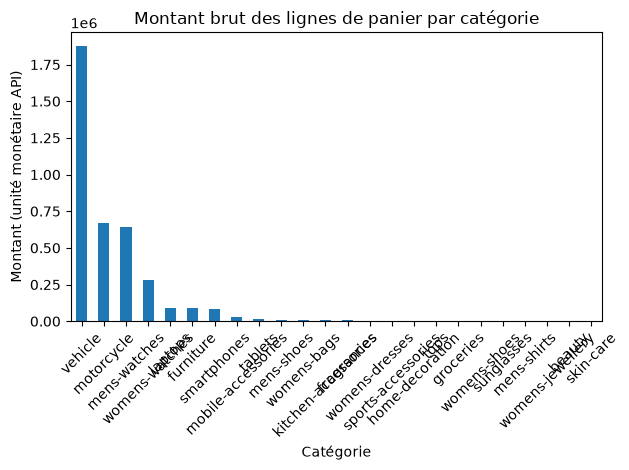

In [10]:
if "category" in df and "line_total" in df:
    ca_categorie = df.groupby("category", dropna=False)["line_total"].sum().sort_values(ascending=False)
    display(ca_categorie.to_frame("total_lignes_panier"))
    ca_categorie.plot(kind="bar", title="Montant brut des lignes de panier par catégorie", ylabel="Montant (unité monétaire API)", xlabel="Catégorie", rot=45)
    plt.tight_layout()
    plt.show()


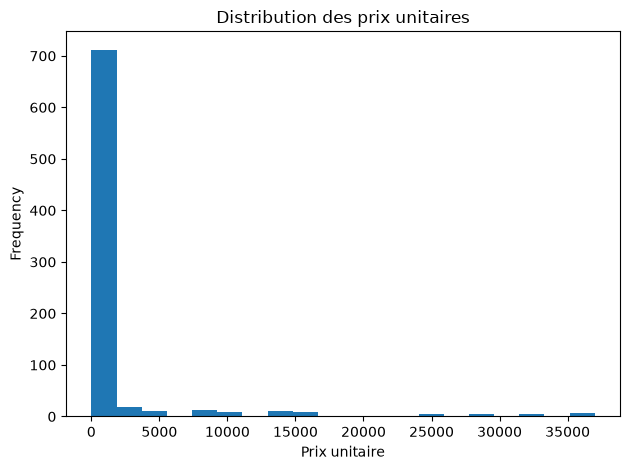

In [11]:
if "unit_price" in df:
    df["unit_price"].dropna().plot(kind="hist", bins=20, title="Distribution des prix unitaires", xlabel="Prix unitaire")
    plt.tight_layout()
    plt.show()


## 7. Construire un jeu nettoyé — sans écraser la source

Conservez `df_brut`. Créez une copie et appliquez des règles explicites. Ne remplacez pas toutes les valeurs manquantes par la chaîne `inconnu` : cela peut transformer des colonnes numériques en texte.


In [12]:
df_clean = df.copy()

# Règles de nettoyage pédagogiques : à adapter après observation des anomalies.
if "quantity" in df_clean:
    df_clean = df_clean[df_clean["quantity"].notna() & (df_clean["quantity"] > 0)]
if "unit_price" in df_clean:
    df_clean = df_clean[df_clean["unit_price"].notna() & (df_clean["unit_price"] >= 0)]
if "cart_id" in df_clean and "product_id" in df_clean:
    df_clean = df_clean.drop_duplicates(subset=["cart_id", "product_id"], keep="first")

print("Avant :", df.shape)
print("Après :", df_clean.shape)


Avant : (800, 16)
Après : (788, 16)


In [13]:
# Sauvegarder dans data/processed/ (ne pas écraser le CSV brut)
OUT = ROOT / "data" / "processed"
OUT.mkdir(parents=True, exist_ok=True)
clean_path = OUT / "commandes_ecommerce_nettoyees.csv"
df_clean.to_csv(clean_path, index=False)
print("Fichier nettoyé enregistré :", clean_path)


Fichier nettoyé enregistré : /home/faton/Documents/FATON/10 - Cours/B2/03 - Bloc Specialisation/E33 - Big Data/TP/BigData_Commerce_Analytics_DummyJSON/data/processed/commandes_ecommerce_nettoyees.csv


## 8. Conclusion et livrable

Rédigez une courte note de qualité contenant :
1. le nombre de lignes et de colonnes ;
2. la granularité du fichier ;
3. les types à corriger ;
4. le nombre de valeurs manquantes et de doublons ;
5. trois anomalies ou limites observées ;
6. les règles de nettoyage retenues ;
7. les précautions à prendre avant chargement dans MongoDB ou Spark.

### Questions de réflexion
- Pourquoi faut-il garder une copie brute ?
- Pourquoi `cart_total` ne doit-il pas être additionné ligne par ligne ?
- Quelle différence entre qualité technique et pertinence métier ?
- Quelles limites viennent de la source DummyJSON plutôt que de votre code ?

**Livrable :** le notebook exécuté, `commandes_ecommerce_nettoyees.csv` et une note de qualité d'une page.
